# 03 Review queue: what the fraud team gets each day

The model ranks every transfer and cash-out. This notebook turns that ranking into the numbers a fraud manager needs:

*"If the team reviews N flags a day, the model catches X% of fraud worth R Y, and Z% of flags are false alarms."*

PaySim amounts are in the simulator's currency units. For this South African framing I read them as rand; the point is the comparison between options, not the exact figure.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd

test = pd.read_parquet("../data/processed/test_scored.parquet")
test["rank_in_day"] = test.groupby("day")["score"].rank(ascending=False, method="first")
n_days = test.day.nunique()
fraud_total = test.loc[test.is_fraud == 1, "amount"].sum()

## 1. The capacity trade-off

In [2]:
rows = []
for n in [50, 100, 150, 200, 250, 300, 400, 500, 750, 1000]:
    q = test[test.rank_in_day <= n]
    rows.append({"reviews per day": n,
                 "fraud caught (%)": 100 * q.is_fraud.sum() / test.is_fraud.sum(),
                 "fraud value caught (%)": 100 * q.loc[q.is_fraud == 1, "amount"].sum() / fraud_total,
                 "flags that are fraud (%)": 100 * q.is_fraud.mean(),
                 "false alarms per day": (q.is_fraud == 0).sum() / n_days})
tradeoff = pd.DataFrame(rows).round(1)
tradeoff.to_csv("../reports/capacity_tradeoff.csv", index=False)
tradeoff

,reviews per day,fraud caught (%),fraud value caught (%),flags that are fraud (%),false alarms per day
0,50,18.7,55.3,100.0,0.0
1,100,37.5,73.2,100.0,0.0
2,150,56.2,82.5,100.0,0.0
3,200,74.9,87.0,100.0,0.0
4,250,93.0,88.7,99.3,1.8
5,300,97.7,89.0,86.9,39.2
6,400,99.7,98.2,66.6,133.8
7,500,100.0,100.0,53.4,233.0
8,750,100.0,100.0,35.6,483.0
9,1000,100.0,100.0,26.7,733.0


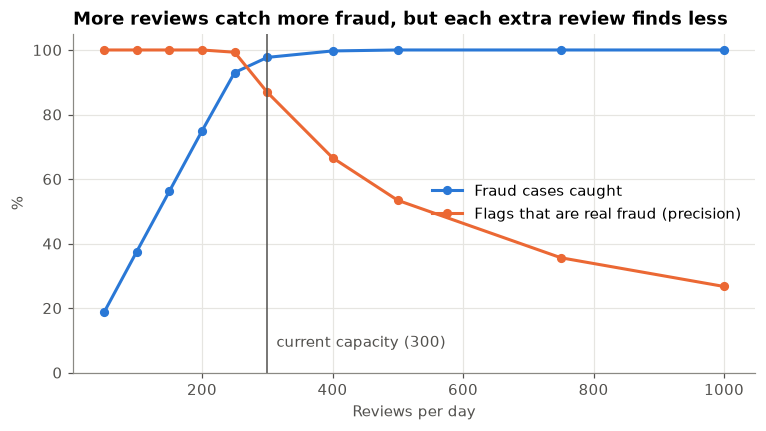

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tradeoff["reviews per day"], tradeoff["fraud caught (%)"], color=BLUE, marker="o", markersize=5, label="Fraud cases caught")
ax.plot(tradeoff["reviews per day"], tradeoff["flags that are fraud (%)"], color=ORANGE, marker="o", markersize=5,
        label="Flags that are real fraud (precision)")
ax.axvline(300, color="#52514e", linewidth=1)
ax.annotate("current capacity (300)", (300, 8), xytext=(6, 0), textcoords="offset points", color="#52514e")
ax.set_xlabel("Reviews per day")
ax.set_ylabel("%")
ax.set_ylim(0, 105)
ax.set_title("More reviews catch more fraud, but each extra review finds less")
ax.legend(loc="center right")
fig.savefig("../figures/capacity_tradeoff.png")
plt.show()

## 2. The sentence for the fraud manager

In [4]:
row = tradeoff.set_index("reviews per day").loc[300]
value_caught = test.loc[(test.rank_in_day <= 300) & (test.is_fraud == 1), "amount"].sum()
print(f"If the team reviews 300 flags a day, the model catches {row['fraud caught (%)']:.0f}% of fraud cases, "
      f"worth about R{value_caught / n_days / 1e6:,.0f} million a day ({row['fraud value caught (%)']:.0f}% of the money stolen), "
      f"and {100 - row['flags that are fraud (%)']:.0f}% of flags are false alarms "
      f"({row['false alarms per day']:.0f} a day).")

If the team reviews 300 flags a day, the model catches 98% of fraud cases, worth about R364 million a day (89% of the money stolen), and 13% of flags are false alarms (39 a day).


## 3. What the queue looks like: one example day

In [5]:
day = sorted(test.day.unique())[-1]
queue = (test[(test.day == day) & (test.rank_in_day <= 300)]
         .sort_values("rank_in_day")
         .assign(type=lambda d: np.where(d.is_transfer == 1, "TRANSFER", "CASH_OUT"),
                 priority=lambda d: pd.cut(d.rank_in_day, [0, 100, 200, 300], labels=["High", "Medium", "Low"])))
export = queue[["rank_in_day", "priority", "hour", "type", "amount", "empties_account", "score"]].rename(
    columns={"rank_in_day": "rank", "empties_account": "takes_full_balance", "score": "model_score"})
export = export.astype({"rank": int}).round({"amount": 2, "model_score": 4})
export.to_csv(f"../reports/review_queue_day{day}.csv", index=False)
print(f"Day {day}: {len(queue)} cases queued, {queue.is_fraud.sum()} turned out to be fraud.")
export.head(10)

Day 16: 300 cases queued, 300 turned out to be fraud.


,rank,priority,hour,type,amount,takes_full_balance,model_score
5563706,1,High,2,CASH_OUT,10000000.00,1,1.0
5563710,2,High,2,CASH_OUT,10000000.00,1,1.0
5563712,3,High,2,CASH_OUT,10000000.00,1,1.0
5563724,4,High,2,CASH_OUT,10000000.00,1,1.0
5563726,5,High,2,CASH_OUT,9110884.44,1,1.0
5724272,6,High,13,CASH_OUT,10000000.00,1,1.0
5563374,7,High,1,TRANSFER,6063657.03,1,1.0
5563508,8,High,1,CASH_OUT,10000000.00,1,1.0
5563725,9,High,2,TRANSFER,9110884.44,1,1.0
5563735,10,High,3,TRANSFER,6703831.40,1,1.0


In [6]:
fraud_q = queue[queue.is_fraud == 1]
pairs = fraud_q.groupby("amount")["type"].nunique().eq(2).sum()
print(f"{pairs} amounts appear in today's queue as both a TRANSFER and a CASH_OUT ({2 * pairs} of {len(fraud_q)} fraud cases)")

140 amounts appear in today's queue as both a TRANSFER and a CASH_OUT (280 of 300 fraud cases)


Many fraud cases come in pairs: a `TRANSFER` and a `CASH_OUT` of the same amount. That is the fraud pattern in the simulator: move the stolen balance to a mule account, then withdraw it. Operationally this matters: **if the transfer is caught and held, the matching cash-out never happens**, so a real-time hold on the transfer is worth more than a review after the cash-out.

In [7]:
by_priority = queue.groupby("priority", observed=True).agg(cases=("is_fraud", "size"), fraud=("is_fraud", "sum"))
by_priority["hit rate"] = (by_priority.fraud / by_priority.cases).round(2)
by_priority

,cases,fraud,hit rate
priority,,,
High,100,100,1.0
Medium,100,100,1.0
Low,100,100,1.0


The false alarms sit almost entirely at the bottom of the queue. In the trade-off table, the first 250 reviews a day are 99% fraud, and nearly all of the roughly 39 daily false alarms come in the last 50. So on a short-staffed day, working the queue from the top loses very little. And because the model ranks the largest thefts first, even the first 50 reviews a day protect over half of the money.